In [1]:
#get important features
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
# 获取己糖醇的特征数据
data = pd.read_csv(r"e:\Data\Ralstonia\newdata\final_knumber\code_data\delete_outlier\training_dataset.csv")
data1 = data.iloc[:, 1:]
data1 = data1.astype(int)

x_disaccharide = data1.iloc[:, 0:-4]
y_disaccharide = data1.loc[:, "disaccharide_metabolism"]
x_hexitol = data1.iloc[:, 0:-4]
y_hexitol = data1.loc[:, "hexitol_metabolism"]

model1 = xgb.XGBClassifier()
model1.fit(x_disaccharide, y_disaccharide);

d:\APP\Programme\Anaconda3\envs\graduation2_xgb\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


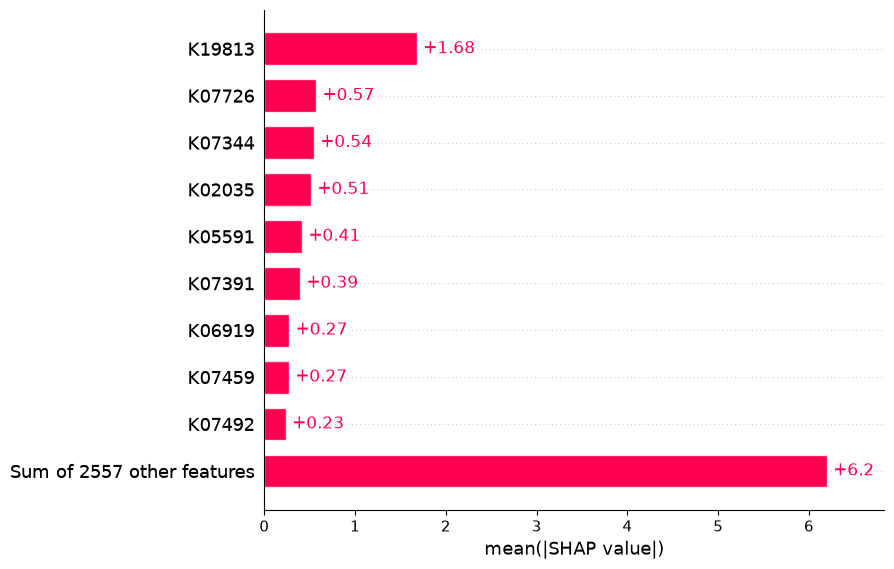

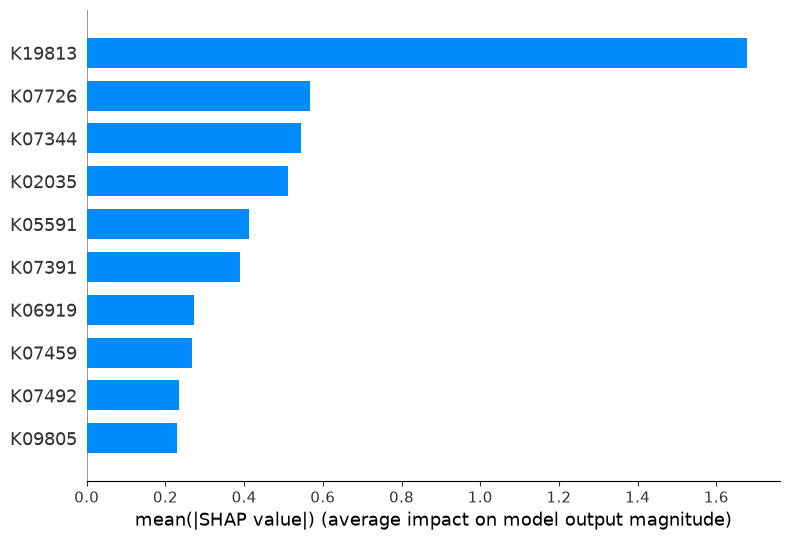

In [2]:
import shap
explainer_disaccharide_raw = shap.TreeExplainer(
    model1,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

shap_values_disaccharide_raw = explainer_disaccharide_raw(
    x_disaccharide
)
shap.plots.bar(
    shap_values_disaccharide_raw,
    max_display=10
)

shap.summary_plot(
    shap_values_disaccharide_raw,
    x_disaccharide,
    plot_type="bar",
    max_display=10
)

In [3]:
# ===================== 提取并打印SHAP数值 =====================

values = np.asarray(
    shap_values_disaccharide_raw.values
)

print("SHAP values shape:", values.shape)


# 获取特征名称
if isinstance(x_disaccharide, pd.DataFrame):
    feature_names = x_disaccharide.columns.astype(str).tolist()
else:
    feature_names = shap_values_disaccharide_raw.feature_names

if feature_names is None:
    feature_names = [
        f"Feature_{i}"
        for i in range(values.shape[1])
    ]


# 计算柱状图对应的mean(|SHAP value|)
if values.ndim == 2:
    # 形状：(样本数, 特征数)
    mean_abs_shap = np.abs(values).mean(axis=0)

elif values.ndim == 3:
    # 形状：(样本数, 特征数, 输出类别数)
    mean_abs_shap = np.abs(values).mean(axis=(0, 2))

else:
    raise ValueError(
        f"无法识别SHAP values的维度：{values.shape}"
    )


# 整理结果
shap_importance_disaccharide = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_SHAP": mean_abs_shap
})

shap_importance_disaccharide = (
    shap_importance_disaccharide
    .sort_values(
        "mean_abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# 打印Top 10
print("\nDisaccharide Top 10 mean(|SHAP value|):")

print(
    shap_importance_disaccharide
    .head(10)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

SHAP values shape: (250, 2566)

Disaccharide Top 10 mean(|SHAP value|):
feature  mean_abs_SHAP
 K19813       1.677941
 K07726       0.568434
 K07344       0.543300
 K02035       0.511452
 K05591       0.412828
 K07391       0.390076
 K06919       0.272541
 K07459       0.268260
 K07492       0.234233
 K09805       0.230690


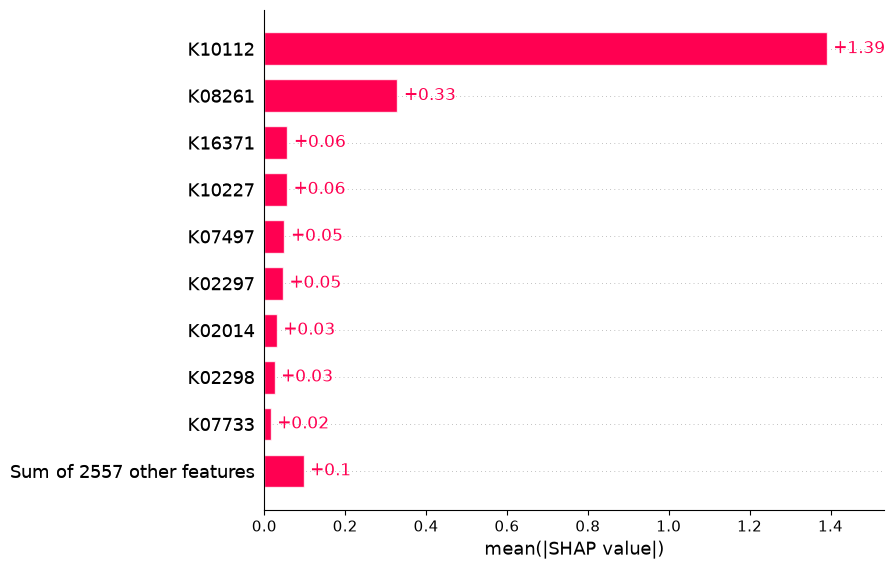

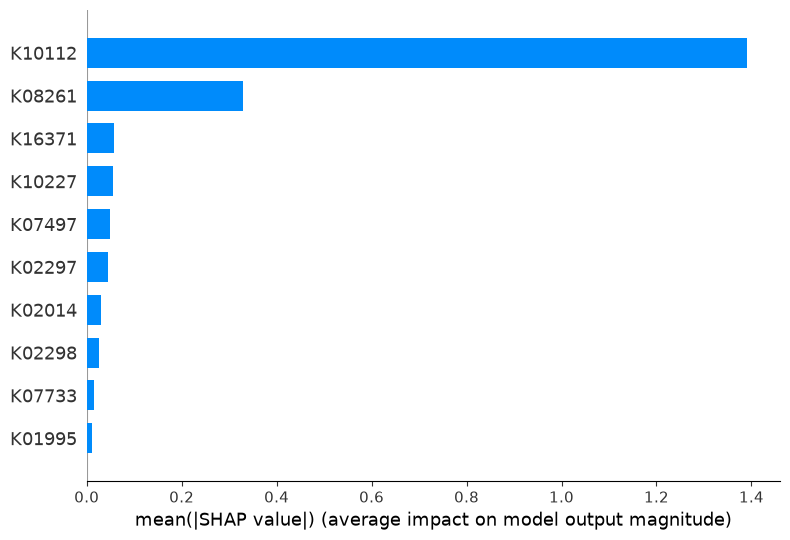

In [4]:
import shap


model2 = xgb.XGBRFClassifier()
model2.fit(x_hexitol, y_hexitol)

explainer_hexitol_raw = shap.TreeExplainer(
    model2,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

shap_values_hexitol_raw = explainer_hexitol_raw(
    x_hexitol
)
shap.plots.bar(
    shap_values_hexitol_raw,
    max_display=10
)

shap.summary_plot(
    shap_values_hexitol_raw,
    x_hexitol,
    plot_type="bar",
    max_display=10
)

In [5]:
# ===================== 提取并打印SHAP数值 =====================

values = np.asarray(
    shap_values_hexitol_raw.values
)

print("SHAP values shape:", values.shape)


# 获取特征名称
if isinstance(x_hexitol, pd.DataFrame):
    feature_names = x_hexitol.columns.astype(str).tolist()
else:
    feature_names = shap_values_hexitol_raw.feature_names

if feature_names is None:
    feature_names = [
        f"Feature_{i}"
        for i in range(values.shape[1])
    ]


# 计算柱状图对应的mean(|SHAP value|)
if values.ndim == 2:
    # 形状：(样本数, 特征数)
    mean_abs_shap = np.abs(values).mean(axis=0)

elif values.ndim == 3:
    # 形状：(样本数, 特征数, 输出类别数)
    mean_abs_shap = np.abs(values).mean(axis=(0, 2))

else:
    raise ValueError(
        f"无法识别SHAP values的维度：{values.shape}"
    )


# 整理结果
shap_importance_hexitol = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_SHAP": mean_abs_shap
})

shap_importance_hexitol = (
    shap_importance_hexitol
    .sort_values(
        "mean_abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# 打印Top 10
print("\nHexitol Top 10 mean(|SHAP value|):")

print(
    shap_importance_hexitol
    .head(10)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

SHAP values shape: (250, 2566)

Hexitol Top 10 mean(|SHAP value|):
feature  mean_abs_SHAP
 K10112       1.390578
 K08261       0.328957
 K16371       0.056995
 K10227       0.056095
 K07497       0.049789
 K02297       0.045811
 K02014       0.030634
 K02298       0.025295
 K07733       0.015635
 K01995       0.012133


In [11]:
model2=model2.get_booster()
importance=model2.get_score(importance_type="gain")
importance=sorted(importance.items(),key=lambda x:x[1],reverse=True)
df=pd.DataFrame(importance,columns=['feature','fscore'])
df['fscore']=df['fscore']/df['fscore'].sum()

print("hexitol")
print(df.loc[0:9, ["feature","fscore"]])

hexitol
  feature    fscore
0  K16371  0.229979
1  K10227  0.227418
2  K08261  0.226025
3  K10112  0.225405
4  K12262  0.003455
5  K16138  0.003223
6  K02298  0.003204
7  K02014  0.003017
8  K02297  0.003014
9  K01751  0.002901
